# Introduction

Exercise designed to use a Maximum Likelihood Estimation and Markov Chain Monte Carlo to estimate the parameters of a damped harmonic oscillator. First, we'll calculate the covariance matrix and mean from 1,000 mock data samples, then next use the observed data to estimate the amplitude, damping parameter, phase angle, and damped angular frequency of the oscillator. 

Using an MCMC analysis will allow us to explore the uncertainty in these parameters, visualize their distributions, and compare our estimates with the known values used to generate the data. Off we go!

In [1]:
%config InlineBackend.figure_format = "retina"

import numpy as np
import matplotlib.pyplot as plt

test_sample = np.loadtxt('samples/oscillator_0001.dat')
data_true = np.loadtxt('oscillator_data.dat')

# What are we working with here
print(f'Data shape test_sample: {test_sample.shape}')
print(f'First 5 rows test_sample: \n{test_sample[:5]}')
print(f'Data shape data_true: {data_true.shape}')
print(f'First 5 rows data_true: {data_true[:5]}')

Data shape test_sample: (50, 2)
First 5 rows test_sample: 
[[0.         0.05344578]
 [0.0121648  0.04701793]
 [0.0243296  0.03814655]
 [0.03649441 0.02179857]
 [0.04865921 0.00263729]]
Data shape data_true: (50, 2)
First 5 rows data_true: [[0.         0.05240046]
 [0.0121648  0.04544184]
 [0.0243296  0.03618029]
 [0.03649441 0.02093554]
 [0.04865921 0.00017628]]


In [2]:
# Very helpful you're code is for calculating the covariance matrix.
N_data = 50
N_samples = 1000
mu = np.zeros(N_data)

for s in range(0, N_samples):
    input_file = 'samples/oscillator_{0:04}.dat'.format(s+1)
    x, y = np.loadtxt(input_file, unpack=True)
    mu += y
# Here's the mean of all the samples.
mu /= N_samples

C = np.zeros((N_data, N_data))
for s in range(0, N_samples):
    input_file = 'samples/oscillator_{0:04}.dat'.format(s+1)
    x, y = np.loadtxt(input_file, unpack=True)
    for i in range(0, N_data):
        for j in range(0, N_data):
            C[i,j] += (y[i] - mu[i])*(y[j] - mu[j])
C /= (N_samples - 1)

## Visualize the covariance matrix

There was a way discussed on how to do this. Let's see if we can't figure it out.

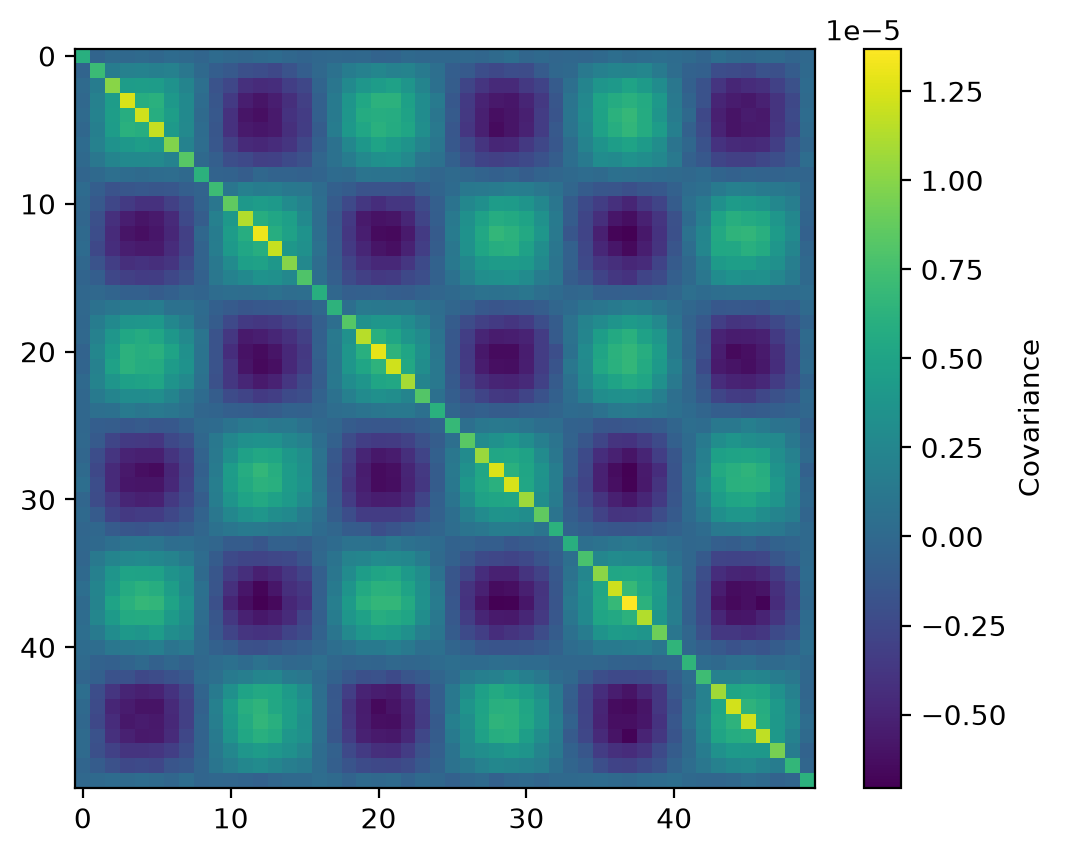

In [3]:
plt.figure()
plt.imshow(C)
plt.colorbar(label='Covariance')
plt.show()

Everything checks out so far. Now we need to write a function that will return the model values when provided with an array of time values and the listed parameters mentioned in the intro above. 

In [4]:
# Damped harmonic oscillator model.
def dho_model(t, A, omega, gamma, phi):
    omega_prime = np.sqrt(omega**2 - gamma**2)
    X_t = A*np.exp(-gamma*t)*np.cos(omega_prime*t + phi)
    return X_t

Next to calculate chi_squared using the inverse covariance matrix.

In [12]:
# Inverse covariance matrix using np.linalg
C_inverse = np.linalg.inv(C)

def chi_squared(parameters, t, y, C_inv):
    A, omega, gamma, phi = parameters
    model = dho_model(t, A, omega, gamma, phi)
    return np.dot((y - model), np.dot(C_inv, (y - model)))

# Separting the times. Double checking that I'm still good with now knowing how these times were calculated. Don't believe any changes are necessary...
t = data_true[:, 0]
y = data_true[:, 1]

## Finding the Maximum Likelihood

Now we're to write a function to compute the negative log-likelihood and minimize it using the minimize function provided by SciPy.

In [6]:
from scipy.optimize import minimize

def neg_log_likelihood(parameters, t, y, C_inverse):
    return 0.5*chi_squared(parameters, t, y, C_inverse)

# Initial parameter guesses (but are they really?? *wink wink*)
initial_parameters = [0.05, np.sqrt(1000), 0.01, 0]

# Didn't need these afterall.
# Let's create some bounds so this doesn't run away on us.
#bounds = [(0.001, 0.1), (25, 35), (0.00001, 0.1), (-1, 1)]

soln = minimize(neg_log_likelihood, initial_parameters, args=(t, y, C_inverse))

# Here's our maximum likelihood estimates.
A_est, omega_est, gamma_est, phi_est = soln.x

print('Maximum likelihood estimates')
print(f'Amplitude {A_est:.6f}')
print(f'Angular frequency: {omega_est:.6f}')
print(f'Damping parameter: {gamma_est:.6f}')
print(f'Phase angle: {phi_est:.6f}')

Maximum likelihood estimates
Amplitude 0.050208
Angular frequency: 31.625309
Damping parameter: -0.008109
Phase angle: -0.009482


Still looking like we're in good shape. Now to define the log-likelihood function, set up the walkers, and set up the ensemble sampler.

In [7]:
def log_likelihood(parameters, t, y, C_inverse):
    # Negating the negative value returned
    return -0.5*chi_squared(parameters, t, y, C_inverse)

def log_prior(parameters):
    A, omega, gamma, phi = parameters
    # Using reasonable bounds after playing with these quite a bit. I know you said we could keep gamma above 0 but this seems to throw off the scale 
    # of the chain plot unless I put in bounds on the minimize function which just seemed to cause additional problems...Either way, this works now!
    if 0.001 < A < 0.1 and 25 < omega < 35 and -0.1 < gamma < 0.1 and -1 < phi < 1:
        return 0.0
    return -np.inf

def log_probability(parameters, t, y, C_inverse):
    lp = log_prior(parameters)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(parameters, t, y, C_inverse)

In [8]:
# As with with most of this code, mostly following along with your examples here.
import emcee

pos = soln.x + 1e-3*np.random.randn(32, 4)
nwalkers, ndim = pos.shape

sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=(t, y, C_inverse))

sampler.run_mcmc(pos, 10000, progress=True);

100%|██████████| 10000/10000 [00:04<00:00, 2085.66it/s]


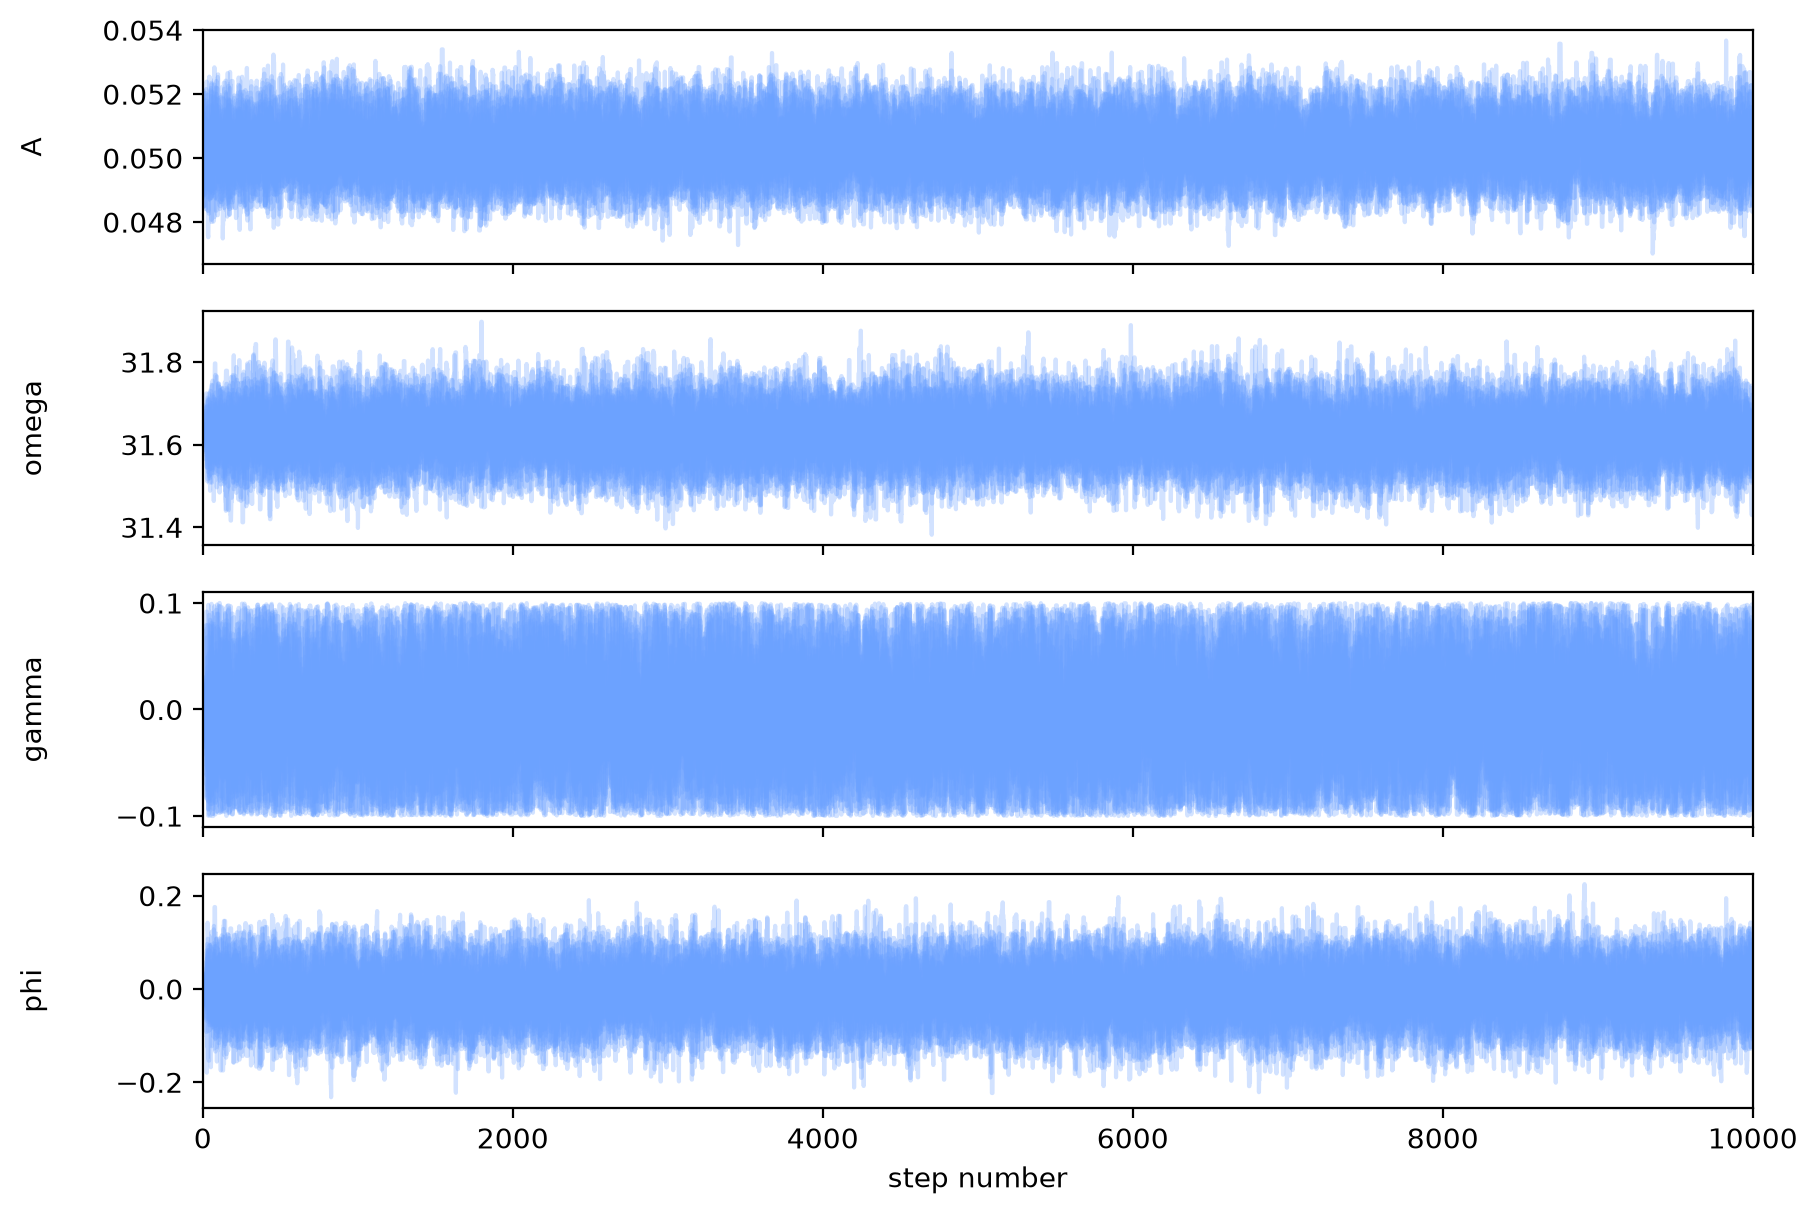

In [9]:
# Again, just mostly using your code here with the slightest modifications.
fig, axes = plt.subplots(4, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
labels = ['A', 'omega', 'gamma', 'phi']
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], alpha=0.3, color="#6CA2FF")
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")
plt.savefig("chain_analysis.pdf", bbox_inches="tight")
plt.show()

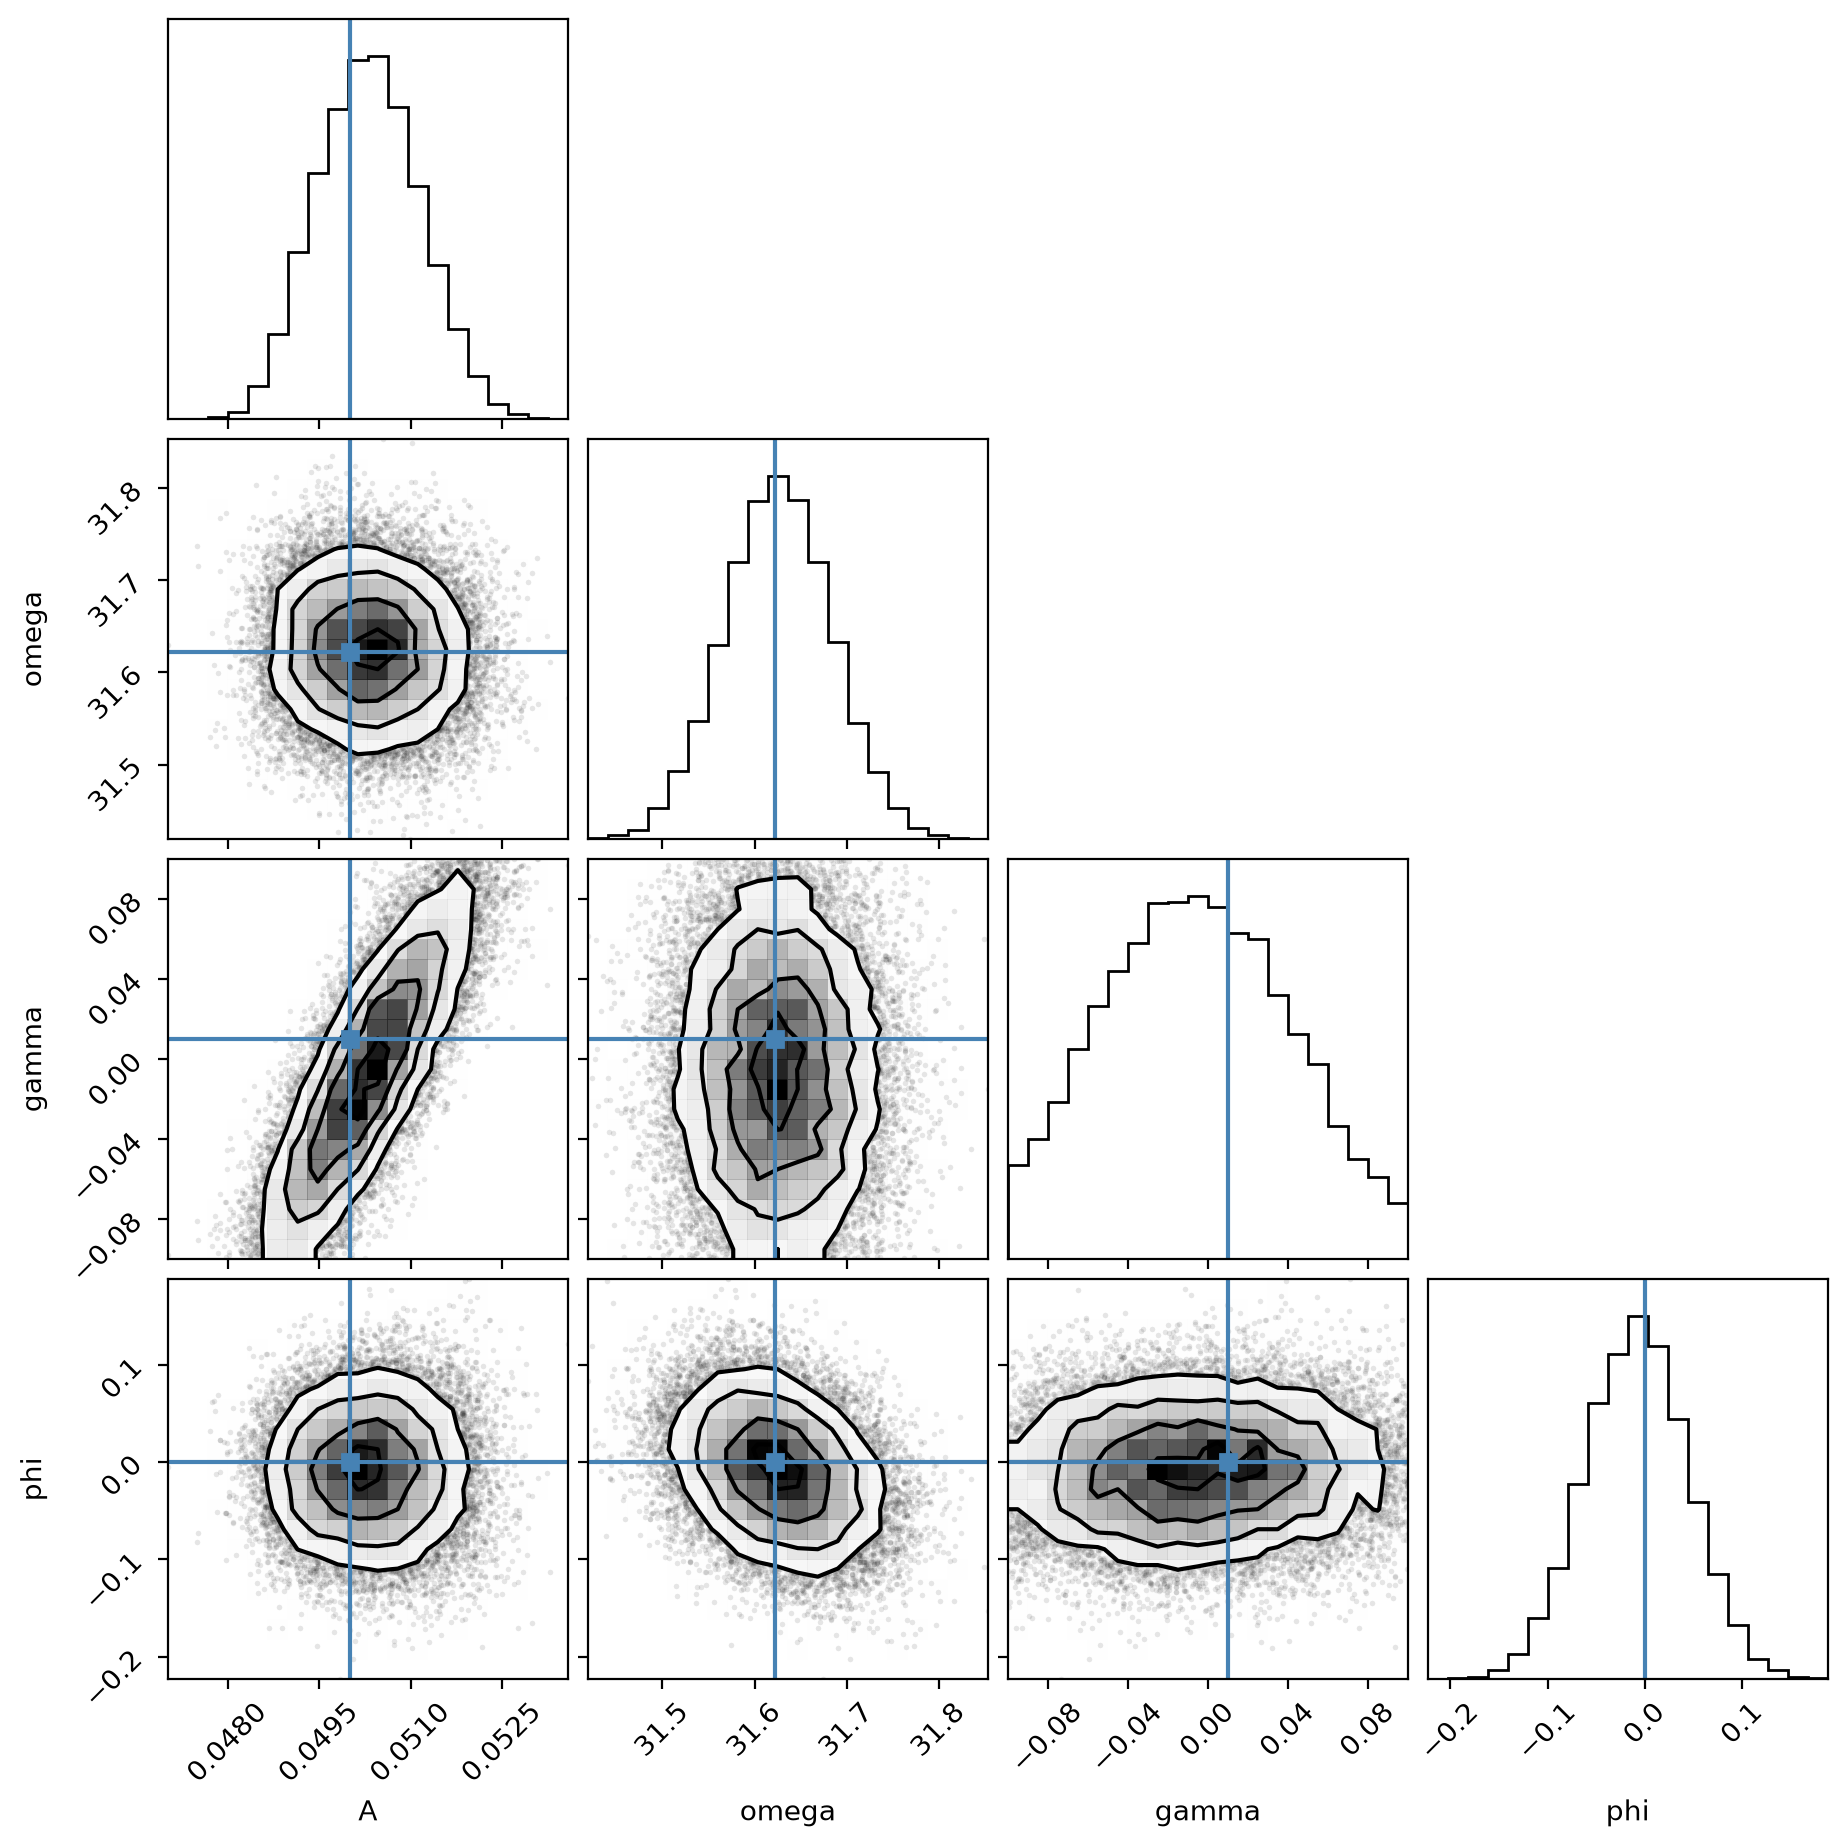

In [10]:
# And again, well, you know...
import corner

A_true = 0.05
omega_true = np.sqrt(1000)
gamma_true = 0.01
phi_true = 0

# Graphs don't seem to show as much of a burn in as yours do, but still appears to be a little something that around 0. I'll leave in the discard. 
flat_samples = sampler.get_chain(discard=100, thin=15, flat=True)

fig = corner.corner(
    flat_samples, labels=labels, truths=[A_true, omega_true, gamma_true, phi_true]
)

plt.savefig("corner.pdf", bbox_inches="tight")
plt.show()

## Finding Confidence Intervals

Finally, we're now to use the MCMC samples in estimating the uncertainty associated with each of our four oscillator paramaters. Making these calculations allows us to compare our estimated paramaters with the known values used and determine whether they are statistically consistent.

In [11]:
# Redefine flat_samples to use unthinned data.
flat_samples = sampler.get_chain(discard=100, flat=True)

A_avg = np.mean(flat_samples.T[0])
omega_avg = np.mean(flat_samples.T[1])
gamma_avg = np.mean(flat_samples.T[2])
phi_avg = np.mean(flat_samples.T[3])

sigma_A = np.std(flat_samples.T[0])
sigma_omega = np.std(flat_samples.T[1])
sigma_gamma = np.std(flat_samples.T[2])
sigma_phi = np.std(flat_samples.T[3])

# Calculating the upper and lower uncertainty.
A_high = A_avg + sigma_A
A_low = A_avg - sigma_A
A_plus = A_high - A_est
A_minus = A_est - A_low

omega_high = omega_avg + sigma_omega
omega_low = omega_avg - sigma_omega
omega_plus = omega_high - omega_est
omega_minus = omega_est - omega_low

gamma_high = gamma_avg + sigma_gamma
gamma_low = gamma_avg - sigma_gamma
gamma_plus = gamma_high - gamma_est
gamma_minus = gamma_est - gamma_low

phi_high = phi_avg + sigma_phi
phi_low = phi_avg - sigma_phi
phi_plus = phi_high - phi_est
phi_minus = phi_est - phi_low

print("Maximum Likelihood Estimates with MCMC errors:")
print("A = {0:.3f} (+{1:.3f}, -{2:.3f})".format(A_est, A_plus, A_minus))
print("Omega = {0:.3f} (+{1:.3f}, -{2:.3f})".format(omega_est, omega_plus, omega_minus))
print("Gamma = {0:.3f} (+{1:.3f}, -{2:.3f})".format(gamma_est, gamma_plus, gamma_minus))
print("Phi = {0:.3f} (+{1:.3f}, -{2:.3f})".format(phi_est, phi_plus, phi_minus))

Maximum Likelihood Estimates with MCMC errors:
A = 0.050 (+0.001, -0.001)
Omega = 31.625 (+0.058, -0.058)
Gamma = -0.008 (+0.047, -0.042)
Phi = -0.009 (+0.053, -0.052)


## Conclusion

All four parameter values are consistent with the actual values used to create the data. The damping parameter does show greater uncertainty than the others, but still within a reasonable range. Looks as though we can indeed count on MCMC to estimate model parameters and quantify their uncertainties. 